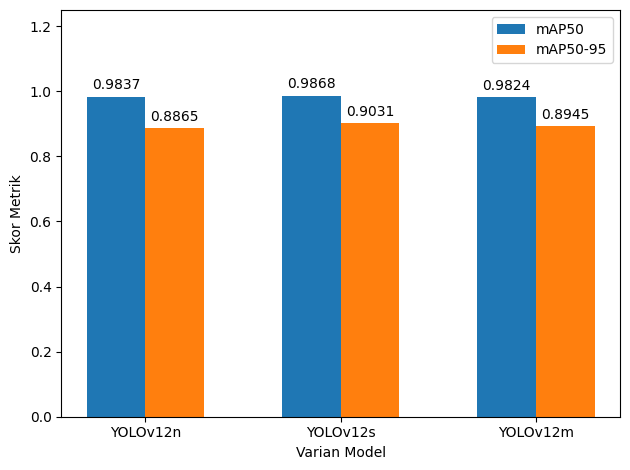

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. KONFIGURASI DIREKTORI MODEL
models_dirs = {
    "YOLOv12n": r"D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\03_Vehicle_Detection\evaluation\evaluation_roi_yolov12n\validation",
    "YOLOv12s": r"D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\03_Vehicle_Detection\evaluation\evaluation_roi_yolov12s\validation",
    "YOLOv12m": r"D:\1-Kuliah\SEKRIPSI\Skripsi_Traffic_Density_Estimation_and_Forecasting\03_Vehicle_Detection\evaluation\evaluation_roi_yolov12m\validation"
}


# 2. EKSTRAKSI DATA METRIK (mAP50 & mAP50-95)
manual_metrics = {
    "YOLOv12n": {"mAP50": 0.9837, "mAP50-95": 0.8865},
    "YOLOv12s": {"mAP50": 0.9868, "mAP50-95": 0.9031},
    "YOLOv12m": {"mAP50": 0.9824, "mAP50-95": 0.8945}
}

results_data = []

for model_name, folder_path in models_dirs.items():
    csv_path = os.path.join(folder_path, "results.csv")
    
    if os.path.exists(csv_path):
        df = pd.read_csv(csv_path)
        df.columns = df.columns.str.strip()
        map50 = df['metrics/mAP50(B)'].max()
        map50_95 = df['metrics/mAP50-95(B)'].max()
    else:
        map50 = manual_metrics[model_name]["mAP50"]
        map50_95 = manual_metrics[model_name]["mAP50-95"]
        
    results_data.append({
        "Model": model_name,
        "mAP50": map50,
        "mAP50-95": map50_95
    })

df_summary = pd.DataFrame(results_data)


# 3. PLOT GRAFIK
x = np.arange(len(df_summary["Model"]))
width = 0.3

fig, ax = plt.subplots()

rects1 = ax.bar(x - width/2, df_summary["mAP50"], width, label='mAP50')
rects2 = ax.bar(x + width/2, df_summary["mAP50-95"], width, label='mAP50-95')

ax.set_ylabel('Skor Metrik')
ax.set_xlabel('Varian Model')
ax.set_xticks(x)
ax.set_xticklabels(df_summary["Model"])
ax.set_ylim(0, 1.25)
ax.legend(loc='upper right')

# Menampilkan nilai angka di atas masing-masing batang
ax.bar_label(rects1, fmt='%.4f', padding=3)
ax.bar_label(rects2, fmt='%.4f', padding=3)

plt.tight_layout()
plt.show()